# Thông tin sinh viên

*   MSSV: xxxxxxx
*   Họ và tên: xxxxxxx

#Bài tập 6

#Kết nối/ Mount đến Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Import thư viện

In [2]:
import cv2
import os
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from tensorflow.keras.applications import imagenet_utils, MobileNetV3Small, MobileNetV3Large
from google.colab.patches import cv2_imshow
import tensorflow as tf
import tensorflow_hub as hub

# Các hàm chung

## Khai báo model MobileNetV3Large

In [3]:
model = MobileNetV3Large();

/usr/local/lib/python3.11/dist-packages/keras/src/applications/mobilenet_v3.py:517: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


22661472/22661472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
def preprocess_img(img):
    resized_img = cv2.resize(img, dsize=(224, 224))
    final_img = np.expand_dims(resized_img, axis=0)
    final_img = tf.keras.applications.mobilenet_v3.preprocess_input(final_img)
    return final_img

In [5]:
def recognizer(final_img):
    predictions = model.predict(final_img, verbose=0)
    results = imagenet_utils.decode_predictions(predictions)

    return results[0][0]

## Sliding window

In [6]:
def ObjLocalization_SW(img,window_size, stride, class_names, confidence_thresshold=0.5):
  detected_objects = []
  # Perform sliding window
  for y in range(0, img.shape[0] - window_size[1], stride):
      for x in range(0, img.shape[1] - window_size[0], stride):
          # Extract window from img
          window = img[y:y+window_size[1], x:x+window_size[0]]
          # Preprocess window for MobileNet input
          preprocessed_window = preprocess_img(window)
          # Make predictions using MobileNet
          _, class_name, confidence = recognizer(preprocessed_window)
          # Check if any object is detected
          if class_name in class_names and confidence>=confidence_thresshold:
              detected_objects.append((class_name, confidence, (x, y, x+window_size[0], y+window_size[1])))
  return detected_objects

## Thuật toán Non max suppression

In [7]:
# Apply non-maximum suppression to remove duplicate detections
def non_max_suppression(detections, threshold):
    if len(detections) == 0:
        return []

    detections_sorted = sorted(detections, key=lambda x: x[1], reverse=True)


    selected_detections = []
    while len(detections_sorted) > 0:
      selected_detections.append(detections_sorted[0])
      detections_sorted.remove(detections_sorted[0])

      for selected_detection in selected_detections:
        _, _, selected_bbox = selected_detection
        selected_x1, selected_y1, selected_x2, selected_y2 = selected_bbox
        for i,detection in enumerate(detections_sorted):
          _, _, bbox = detection
          x1, y1, x2, y2 = bbox
          iou = 0
          xA = max(x1, selected_x1)
          yA = max(y1, selected_y1)
          xB = min(x2, selected_x2)
          yB = min(y2, selected_y2)

          intersection_area = max(0, xB - xA + 1) * max(0, yB - yA + 1)
          bbox_area = (x2 - x1 + 1) * (y2 - y1 + 1)
          selected_bbox_area = (selected_x2 - selected_x1 + 1) * (selected_y2 - selected_y1 + 1)
          iou = intersection_area / float(bbox_area + selected_bbox_area - intersection_area)
          if iou > threshold:
            #print("\n Xoa pt: ",i)
            detections_sorted.remove(detections_sorted[i])

    return selected_detections

# Yêu cầu 1:
* Phát hiện các vị trí có chứa đối tượng Dog trong ảnh dog01.jpg
* Vị trí (hay được gọi là bounding box) được mô tả gồm 4 giá trị tọa độ: left, top, right, bottom
* Sử dụng mô hình pretrained của MobileNet hoặc VGG,… để xác định loại đối tượng.
* Vẽ các bounding box có chứa đối tượng Dog bằng hình chữ nhật có màu Red


## Áp dụng trên ảnh

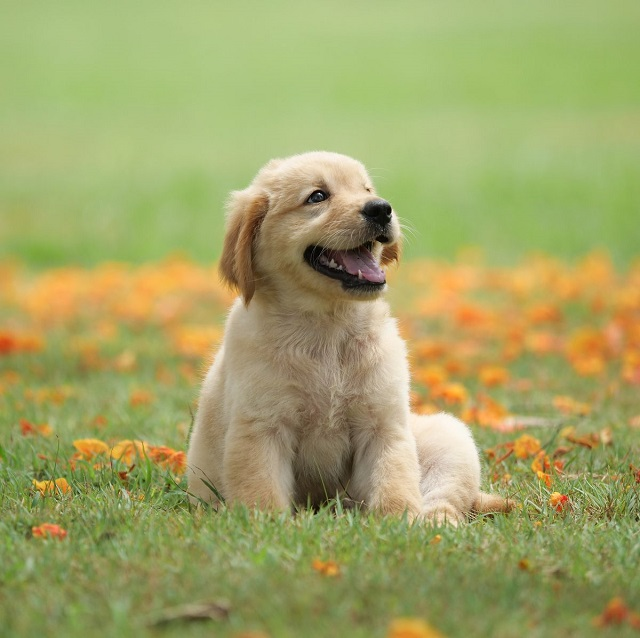

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [8]:
# Define sliding window parameters
window_size = (320, 360)  # Kích thước cửa sổ
stride = 20  # Bước trượt
class_names = ['golden_retriever']

# importing image
filename = '/content/drive/MyDrive/CS231/Baitap6/images/dog01.jpg'

img_dog = cv2.imread(filename)[..., ::-1]
cv2_imshow(img_dog[..., ::-1])
#img_dog = cv2.cvtColor(img_dog, cv2.COLOR_BGR2RGB)

detected_objects = ObjLocalization_SW(img_dog,window_size, stride, class_names)

## Vẽ các bounding box

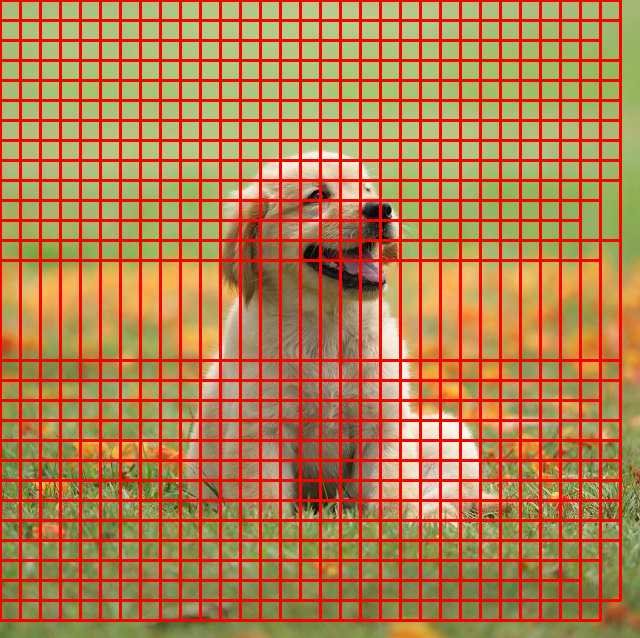

In [9]:
img_res = cv2.cvtColor(img_dog.copy(), cv2.COLOR_BGR2RGB)
for detection in detected_objects:
    class_name, confidence, bbox = detection
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)
cv2_imshow(img_res)

## Áp dụng NMS

In [10]:
selected_detections = non_max_suppression(detected_objects, 0.3)

In [11]:
for detection in selected_detections:
    class_name, confidence, bbox = detection
    img_res = cv2.cvtColor(img_dog.copy(), cv2.COLOR_BGR2RGB)
    if confidence < 0.8:
        continue
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)
    cv2_imshow(img_res)



Output hidden; open in https://colab.research.google.com to view.

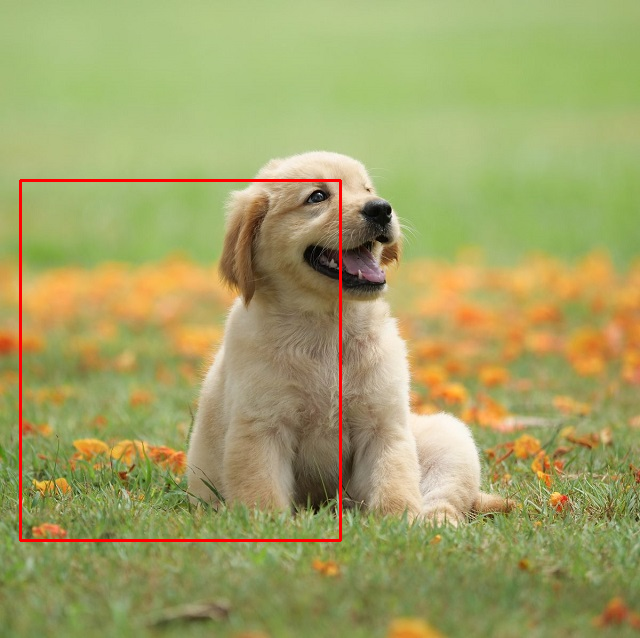

In [12]:
img_res = cv2.cvtColor(img_dog.copy(), cv2.COLOR_BGR2RGB)
detection = selected_detections[0];
class_name, confidence, bbox = detection
x1, y1, x2, y2 = bbox
cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)
cv2_imshow(img_res)


# Yêu cầu 2:
* Phát hiện các vị trí có chứa đối tượng Dog, Cat trong ảnh dogcat.jpg
* Vẽ các bounding box có chứa đối tượng Dog bằng hình chữ nhật có màu Red
* Vẽ các bounding box có chứa đối tượng Cat bằng hình chữ nhật có màu Green

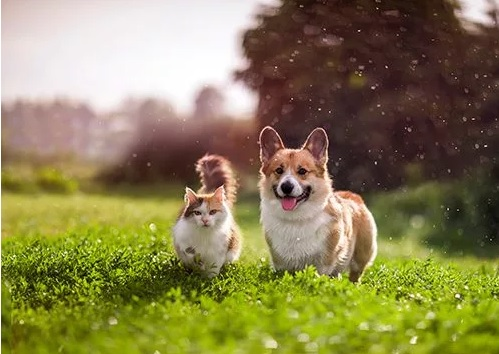

In [13]:
# importing image
filename = '/content/drive/MyDrive/CS231/Baitap6/images/dogcat.jpg'

img_dogcat = cv2.imread(filename)[..., ::-1]
cv2_imshow(img_dogcat[..., ::-1])

# Khai báo model

In [14]:
cat_classes = ['Egyptian_cat', 'Persian_cat', 'tabby', 'Angora']
dog_classes = ['Pembroke', 'Cardigan']

# Sliding window

## Dog

In [15]:
# Define sliding window parameters
window_size = (140, 180)  # Kích thước cửa sổ
stride = 20  # Bước trượt
detected_dog = ObjLocalization_SW( img_dogcat, window_size, stride, dog_classes)

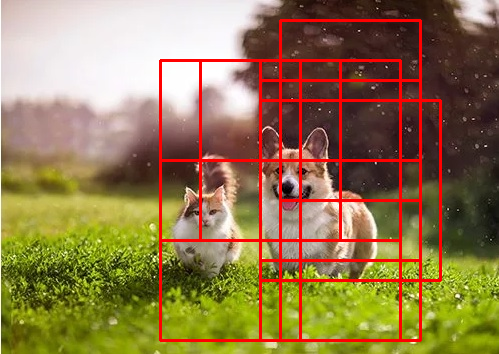

In [16]:
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
for detection in detected_dog:
    class_name, confidence, bbox = detection
    if confidence < 0.7:
        continue
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)

cv2_imshow(img_res)

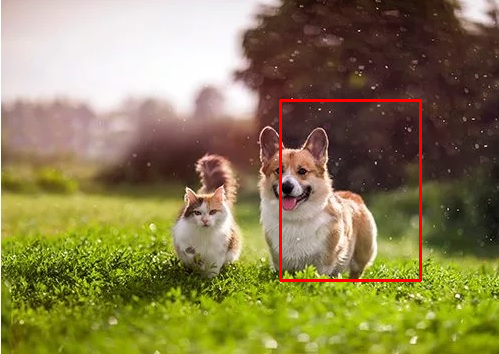

In [17]:
selected_dog = non_max_suppression(detected_dog, 0.3)
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
for detection in selected_dog:
    class_name, confidence, bbox = detection
    if confidence < 0.8:
        continue
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)

cv2_imshow(img_res)

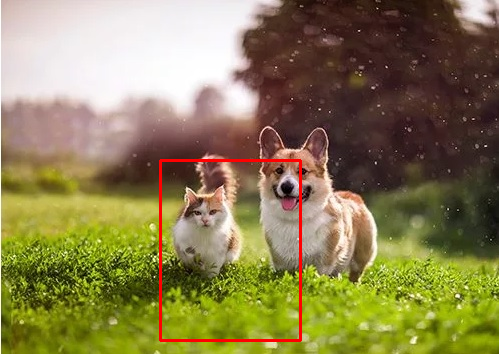

In [18]:
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
class_name, confidence, bbox = selected_dog[2]
x1, y1, x2, y2 = bbox
cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)
cv2_imshow(img_res)

In [19]:
selected_dog

[('Pembroke', np.float32(0.81144273), (280, 100, 420, 280)),
 ('Pembroke', np.float32(0.7639617), (280, 160, 420, 340)),
 ('Pembroke', np.float32(0.72304004), (160, 160, 300, 340)),
 ('Pembroke', np.float32(0.7223632), (200, 60, 340, 240)),
 ('Pembroke', np.float32(0.6587071), (200, 80, 340, 260))]

## Cat

In [20]:
# Define sliding window parameters
window_size = (95, 140)  # Kích thước cửa sổ
stride = 15  # Bước trượt

detected_cat = ObjLocalization_SW( img_dogcat, window_size, stride, cat_classes, 0.3)

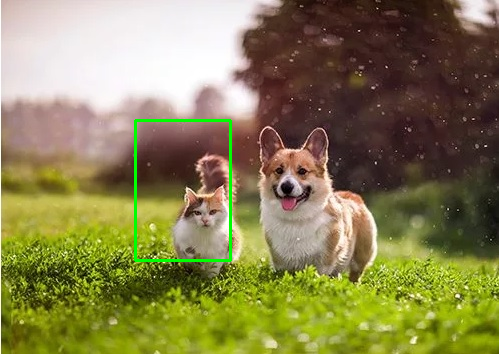

In [21]:
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
for detection in detected_cat:
    class_name, confidence, bbox = detection
    if confidence < 0.2:
        continue
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 255, 0), 2)

cv2_imshow(img_res)

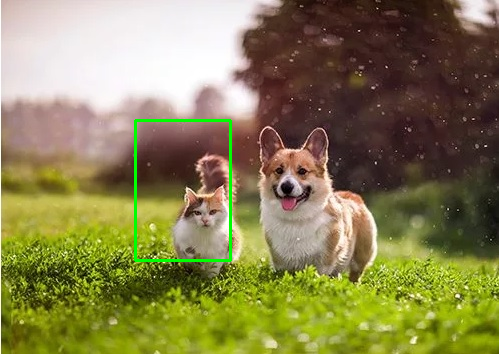

In [22]:
selected_cat = non_max_suppression(detected_cat, 0.1)
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
for detection in selected_cat:
    class_name, confidence, bbox = detection
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 255, 0), 2)

cv2_imshow(img_res)

# Result

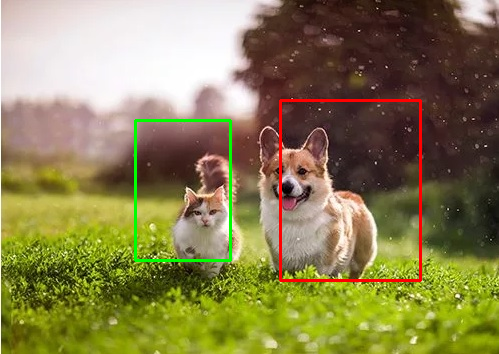

In [23]:
img_res = cv2.cvtColor(img_dogcat.copy(), cv2.COLOR_BGR2RGB)
for detection in selected_dog:
    class_name, confidence, bbox = detection
    if confidence < 0.8:
        continue
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 0, 255), 2)

for detection in selected_cat:
    class_name, confidence, bbox = detection
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img_res, (x1, y1), (x2, y2), (0, 255, 0), 2)

cv2_imshow(img_res)